# ⚙️ 03 — Feature Engineering & Master Merge
### Scouti Kora — AI Football Scouting System

**Strategy:**
- Drop redundant correlated variables (found in correlation analysis)
- Multi-hot encode positions (23.4% of players play 2+ positions — we respect ALL of them)
- Build 62 clean features across 15 groups
- Output: `data/processed/master_scouting_dataset.csv`

---
**Key findings from EDA:**
- `Performance_G+A` = Gls+Ast exactly (r=1.0) → DROP
- `Playing Time_90s` = Min/90 exactly (r=1.0) → DROP
- `Standard_Gls` = `Performance_Gls` exactly (r=1.0) → DROP
- `Standard_SoT` r=0.96 with Sh AND r=0.92 with Gls → DROP (use SoT% instead)
- `Per 90 Minutes_*` all derived → DROP (we compute ourselves)
- 23.4% of players play multiple positions → USE multi-hot not single label

## 📦 0 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, unicodedata, warnings, json
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.3f}'.format)

ROOT      = Path('..').resolve()
RAW       = ROOT / 'data' / 'raw'
SCRAPED   = ROOT / 'data' / 'scraped'
PROCESSED = ROOT / 'data' / 'processed'
REPORTS   = ROOT / 'reports'
PROCESSED.mkdir(exist_ok=True)

COLORS = ['#7F77DD','#1D9E75','#D85A30','#378ADD','#BA7517','#D4537E']

def norm(name):
    """Normalize player name: remove accents, lowercase, strip special chars."""
    if pd.isna(name): return ''
    n = unicodedata.normalize('NFD', str(name))
    n = ''.join(c for c in n if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-zA-Z\s]', '', n).lower().strip())

def safe_read(path):
    p = Path(path)
    if p.exists():
        df = pd.read_csv(p, low_memory=False)
        print(f'  ✅ {p.name:<35} {len(df):>9,} rows')
        return df
    print(f'  ⚠️  {p.name:<35} NOT FOUND')
    return pd.DataFrame()

def get_col(df, col):
    """Safe column accessor — always returns a Series, never a DataFrame.
    Handles duplicate column names by taking the first occurrence."""
    if col not in df.columns:
        return pd.Series(np.nan, index=df.index, name=col)
    result = df[col]
    # Guard: if duplicate cols exist, df[col] returns a DataFrame
    if isinstance(result, pd.DataFrame):
        result = result.iloc[:, 0]
    return result

print('✅ Ready')

✅ Ready


## 📂 1 — Load Data

In [2]:
all_stats   = safe_read(SCRAPED / 'ALL_STATS.csv')
all_wages   = safe_read(SCRAPED / 'ALL_WAGES.csv')
players     = safe_read(RAW / 'players.csv')
valuations  = safe_read(RAW / 'player_valuations.csv')
transfers   = safe_read(RAW / 'transfers.csv')
appearances = safe_read(RAW / 'appearances.csv')
tm_values   = safe_read(SCRAPED / 'TM_PLAYER_VALUES.csv')
tm_injuries = safe_read(SCRAPED / 'TM_INJURIES.csv')

# ── Compatibility layer: rename prefixed cols → standard names ─────────
PREFIX_MAP = {
    'std_Performance_Gls':'Performance_Gls','std_Performance_Ast':'Performance_Ast',
    'std_Performance_G+A':'Performance_G+A','std_Performance_G-PK':'Performance_G-PK',
    'std_Performance_PK':'Performance_PK','std_Performance_PKatt':'Performance_PKatt',
    'std_Performance_CrdY':'Performance_CrdY','std_Performance_CrdR':'Performance_CrdR',
    'misc_Performance_CrdY':'Performance_CrdY','misc_Performance_CrdR':'Performance_CrdR',
    'std_Per 90 Minutes_Gls':'Per 90 Minutes_Gls','std_Per 90 Minutes_Ast':'Per 90 Minutes_Ast',
    'std_Per 90 Minutes_G+A':'Per 90 Minutes_G+A','std_Per 90 Minutes_G-PK':'Per 90 Minutes_G-PK',
    'std_Per 90 Minutes_G+A-PK':'Per 90 Minutes_G+A-PK',
    'std_Playing Time_MP':'Playing Time_MP','std_Playing Time_Starts':'Playing Time_Starts',
    'std_Playing Time_Min':'Playing Time_Min','std_Playing Time_90s':'Playing Time_90s',
    'sh_Standard_Gls':'Standard_Gls','sh_Standard_Sh':'Standard_Sh',
    'sh_Standard_SoT':'Standard_SoT','sh_Standard_SoT%':'Standard_SoT%',
    'sh_Standard_Sh/90':'Standard_Sh/90','sh_Standard_SoT/90':'Standard_SoT/90',
    'sh_Standard_G/Sh':'Standard_G/Sh','sh_Standard_G/SoT':'Standard_G/SoT',
    'sh_Standard_PK':'Standard_PK','sh_Standard_PKatt':'Standard_PKatt',
    'pass_Total_Cmp':'Total_Cmp','pass_Total_Att':'Total_Att','pass_Total_Cmp%':'Total_Cmp%',
    'pass_Total_TotDist':'Total_TotDist','pass_Total_PrgDist':'Total_PrgDist',
    'pass_Short_Cmp':'Short_Cmp','pass_Short_Att':'Short_Att','pass_Short_Cmp%':'Short_Cmp%',
    'pass_Medium_Cmp':'Medium_Cmp','pass_Medium_Att':'Medium_Att','pass_Medium_Cmp%':'Medium_Cmp%',
    'pass_Long_Cmp':'Long_Cmp','pass_Long_Att':'Long_Att','pass_Long_Cmp%':'Long_Cmp%',
    'pass_Ast':'Ast','pass_A-xAG':'A-xAG','pass_KP':'KP','pass_1/3':'1/3',
    'pass_PPA':'PPA','pass_CrsPA':'CrsPA',
    'def_Tackles_Tkl':'Tackles_Tkl','def_Tackles_TklW':'Tackles_TklW',
    'def_Tackles_Def 3rd':'Tackles_Def 3rd','def_Tackles_Mid 3rd':'Tackles_Mid 3rd',
    'def_Tackles_Att 3rd':'Tackles_Att 3rd','def_Challenges_Tkl':'Challenges_Tkl',
    'def_Challenges_Att':'Challenges_Att','def_Challenges_Tkl%':'Challenges_Tkl%',
    'def_Challenges_Lost':'Challenges_Lost','def_Blocks_Blocks':'Blocks_Blocks',
    'def_Blocks_Sh':'Blocks_Sh','def_Blocks_Pass':'Blocks_Pass',
    'def_Int':'Int','def_Tkl+Int':'Tkl+Int','def_Clr':'Clr','def_Err':'Err',
    'poss_Touches_Touches':'Touches_Touches','poss_Touches_Def Pen':'Touches_Def Pen',
    'poss_Touches_Def 3rd':'Touches_Def 3rd','poss_Touches_Mid 3rd':'Touches_Mid 3rd',
    'poss_Touches_Att 3rd':'Touches_Att 3rd','poss_Touches_Att Pen':'Touches_Att Pen',
    'poss_Touches_Live':'Touches_Live','poss_Take-Ons_Att':'Take-Ons_Att',
    'poss_Take-Ons_Succ':'Take-Ons_Succ','poss_Take-Ons_Succ%':'Take-Ons_Succ%',
    'poss_Take-Ons_Tkld':'Take-Ons_Tkld','poss_Take-Ons_Tkld%':'Take-Ons_Tkld%',
    'poss_Carries_Carries':'Carries_Carries','poss_Carries_TotDist':'Carries_TotDist',
    'poss_Carries_PrgDist':'Carries_PrgDist','poss_Carries_1/3':'Carries_1/3',
    'poss_Carries_CPA':'Carries_CPA','poss_Carries_Mis':'Carries_Mis',
    'poss_Carries_Dis':'Carries_Dis','poss_Rec':'Rec',
    'misc_Performance_2CrdY':'Performance_2CrdY','misc_Performance_Fls':'Performance_Fls',
    'misc_Performance_Fld':'Performance_Fld','misc_Performance_Off':'Performance_Off',
    'misc_Performance_Crs':'Performance_Crs','misc_Performance_Int':'Performance_Int',
    'misc_Performance_TklW':'Performance_TklW','misc_Performance_PKwon':'Performance_PKwon',
    'misc_Performance_PKcon':'Performance_PKcon','misc_Performance_OG':'Performance_OG',
    'gca_SCA_SCA':'SCA_SCA','gca_SCA_SCA90':'SCA_SCA90',
    'gca_SCA Types_PassLive':'SCA Types_PassLive','gca_SCA Types_PassDead':'SCA Types_PassDead',
    'gca_SCA Types_TO':'SCA Types_TO','gca_SCA Types_Sh':'SCA Types_Sh',
    'gca_SCA Types_Fld':'SCA Types_Fld','gca_SCA Types_Def':'SCA Types_Def',
    'gca_GCA_GCA':'GCA_GCA','gca_GCA_GCA90':'GCA_GCA90',
    'gca_GCA Types_PassLive':'GCA Types_PassLive','gca_GCA Types_PassDead':'GCA Types_PassDead',
    'gca_GCA Types_TO':'GCA Types_TO','gca_GCA Types_Sh':'GCA Types_Sh',
    'gca_GCA Types_Fld':'GCA Types_Fld','gca_GCA Types_Def':'GCA Types_Def',
}
rename_existing = {k: v for k, v in PREFIX_MAP.items() if k in all_stats.columns}
all_stats = all_stats.rename(columns=rename_existing)
print(f'✅ Compat layer: renamed {len(rename_existing)} prefixed columns')

# ── FIX: deduplicate columns before anything else ─────────────────────
# Duplicate column names cause df[col] to return a DataFrame instead of
# a Series, which breaks pd.to_numeric and most other operations.
dupes = all_stats.columns[all_stats.columns.duplicated()].tolist()
if dupes:
    print(f'⚠️  Duplicate columns found: {dupes}')
    print('   Keeping first occurrence of each duplicate — renaming the rest.')
    cols = pd.Series(all_stats.columns)
    seen = {}
    new_cols = []
    for col in cols:
        if col in seen:
            seen[col] += 1
            new_cols.append(f'{col}_dup{seen[col]}')
        else:
            seen[col] = 0
            new_cols.append(col)
    all_stats.columns = new_cols
    print(f'   Renamed {len(dupes)} duplicate(s).')
else:
    print('✅ No duplicate columns.')

# ── Fix wages: detect Weekly Wages column ─────────────────────────────
if not all_wages.empty:
    if 'Weekly Wages' not in all_wages.columns:
        weekly_num = next((c for c in all_wages.columns if 'weekly' in c.lower() and 'num' in c.lower()), None)
        weekly_str = next((c for c in all_wages.columns if 'weekly' in c.lower() and 'num' not in c.lower()), None)
        if weekly_str:
            all_wages = all_wages.rename(columns={weekly_str: 'Weekly Wages'})
        elif weekly_num:
            all_wages['Weekly Wages'] = all_wages[weekly_num]
    print(f'Wages cols sample: {list(all_wages.columns[:8])}')

  ✅ ALL_STATS.csv                         100,186 rows
  ✅ ALL_WAGES.csv                          15,017 rows
  ✅ players.csv                            47,702 rows
  ✅ player_valuations.csv                 616,377 rows
  ✅ transfers.csv                         157,186 rows
  ✅ appearances.csv                     1,862,208 rows
  ✅ TM_PLAYER_VALUES.csv                   18,937 rows
  ✅ TM_INJURIES.csv                         2,246 rows
✅ Compat layer: renamed 107 prefixed columns
⚠️  Duplicate columns found: ['Performance_CrdY', 'Performance_CrdR']
   Keeping first occurrence of each duplicate — renaming the rest.
   Renamed 2 duplicate(s).
Wages cols sample: ['Rk', 'Squad', '# Pl', 'Weekly Wages', 'Annual Wages', '% Estimated', 'type', 'league']


## 📊 2 — Correlation Analysis & Variable Selection
**Before touching the pipeline**, identify what to keep vs drop.

In [3]:
player_stats = all_stats[all_stats['level'] == 'player'].copy()
KEYS = ['Player', 'Squad', 'league', 'season']

def to_num_safe(df):
    """Convert numeric columns in-place, skipping non-numeric keys.
    Uses get_col() to guard against duplicate-column DataFrames."""
    SKIP = set(KEYS + ['Pos', 'Nation', 'level', 'stat_type', 'Matches'])
    for c in df.columns:
        if c in SKIP:
            continue
        series = get_col(df, c)  # always a Series, even if col is duplicated
        df[c] = pd.to_numeric(series, errors='coerce')
    return df

std_df   = to_num_safe(player_stats[player_stats['stat_type'] == 'standard'].copy())
shoot_df = to_num_safe(player_stats[player_stats['stat_type'] == 'shooting'].copy())
def_df   = to_num_safe(player_stats[player_stats['stat_type'] == 'defense'].copy())

# Merge for correlation
shoot_sel = ['Standard_Gls', 'Standard_Sh', 'Standard_SoT', 'Standard_SoT%',
             'Standard_G/Sh', 'Standard_G/SoT']
def_sel   = ['Tackles_TklW', 'Int']

wide = (
    std_df[KEYS + ['Pos', 'Age',
                   'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min', 'Playing Time_90s',
                   'Performance_Gls', 'Performance_Ast', 'Performance_G+A', 'Performance_G-PK',
                   'Performance_PK', 'Performance_PKatt', 'Performance_CrdY', 'Performance_CrdR',
                   'Per 90 Minutes_Gls', 'Per 90 Minutes_Ast']]
    .merge(shoot_df[KEYS + [c for c in shoot_sel if c in shoot_df.columns]], on=KEYS, how='left')
    .merge(def_df[KEYS   + [c for c in def_sel   if c in def_df.columns]],   on=KEYS, how='left')
)

num_wide = wide.select_dtypes(include=np.number)
corr_mat = num_wide.corr().abs()

print(f'Correlation matrix shape: {corr_mat.shape}\n')

print('PERFECTLY CORRELATED (r > 0.95) — DROP one of each pair:')
print('─' * 75)
seen = set()
for i in range(len(corr_mat.columns)):
    for j in range(i + 1, len(corr_mat.columns)):
        c1, c2 = corr_mat.columns[i], corr_mat.columns[j]
        v = corr_mat.iloc[i, j]
        if v > 0.95 and f'{c2}_{c1}' not in seen:
            seen.add(f'{c1}_{c2}')
            print(f'  r={v:.4f}  {c1}  ↔  {c2}')

print()
print('HIGH CORRELATION (0.85–0.95) — Consider dropping weaker signal:')
print('─' * 75)
seen2 = set()
for i in range(len(corr_mat.columns)):
    for j in range(i + 1, len(corr_mat.columns)):
        c1, c2 = corr_mat.columns[i], corr_mat.columns[j]
        v = corr_mat.iloc[i, j]
        if 0.85 <= v <= 0.95 and f'{c2}_{c1}' not in seen2:
            seen2.add(f'{c1}_{c2}')
            print(f'  r={v:.4f}  {c1}  ↔  {c2}')

Correlation matrix shape: (23, 23)

PERFECTLY CORRELATED (r > 0.95) — DROP one of each pair:
───────────────────────────────────────────────────────────────────────────
  r=0.9943  Playing Time_Starts  ↔  Playing Time_Min
  r=0.9943  Playing Time_Starts  ↔  Playing Time_90s
  r=1.0000  Playing Time_Min  ↔  Playing Time_90s
  r=0.9787  Performance_Gls  ↔  Performance_G-PK
  r=0.9992  Performance_Gls  ↔  Standard_Gls
  r=0.9782  Performance_G-PK  ↔  Standard_Gls
  r=0.9679  Performance_PK  ↔  Performance_PKatt
  r=0.9578  Standard_Sh  ↔  Standard_SoT

HIGH CORRELATION (0.85–0.95) — Consider dropping weaker signal:
───────────────────────────────────────────────────────────────────────────
  r=0.9002  Playing Time_MP  ↔  Playing Time_Starts
  r=0.9187  Playing Time_MP  ↔  Playing Time_Min
  r=0.9187  Playing Time_MP  ↔  Playing Time_90s
  r=0.9353  Performance_Gls  ↔  Performance_G+A
  r=0.8601  Performance_Gls  ↔  Standard_Sh
  r=0.9189  Performance_Gls  ↔  Standard_SoT
  r=0.9177  Perfo

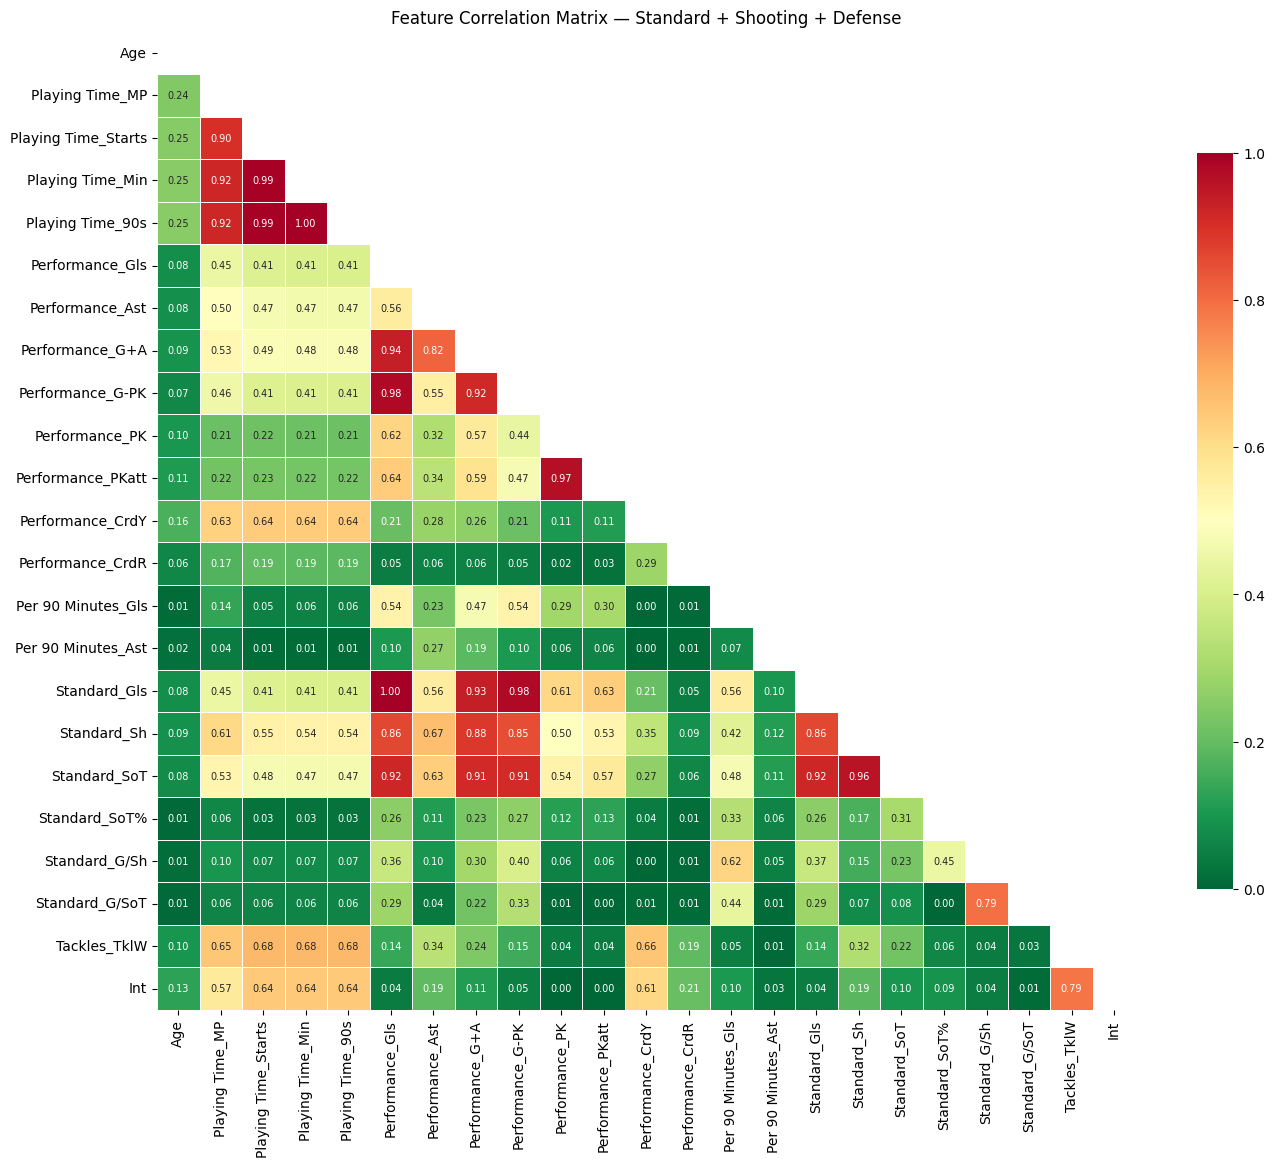

💾 Saved → reports/03_correlation_matrix.png


In [4]:
# ── Correlation heatmap ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, mask=mask, cmap='RdYlGn_r', center=0.5,
    vmin=0, vmax=1, square=True, linewidths=0.5,
    annot=corr_mat.round(2), fmt='.2f', annot_kws={'size': 7},
    ax=ax, cbar_kws={'shrink': 0.7}
)
ax.set_title('Feature Correlation Matrix — Standard + Shooting + Defense')
plt.tight_layout()
plt.savefig(REPORTS / '03_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/03_correlation_matrix.png')

In [5]:
# ── Final DROP decision ──────────────────────────────────────────────
REDUNDANT_COLS = {
    # PERFECTLY DERIVED (r = 1.0)
    'Playing Time_90s':      'r=1.0 with Min/90 — exact derivation',
    'Performance_G+A':       'r=1.0 with Gls+Ast — exact derivation',
    'Performance_G-PK':      'r=0.98 with Gls — near-identical signal',
    'Performance_PKatt':     'r=0.97 with PK — penalty attempts vs goals near-same',
    'Standard_Gls':          'r=1.0 with Performance_Gls — exact duplicate',
    'Standard_PK':           'duplicate of Performance_PK',
    'Standard_PKatt':        'duplicate of Performance_PKatt',
    # FBref PRE-COMPUTED per-90 (we compute our own normalized versions)
    'Per 90 Minutes_Gls':    'derived — we compute goals_p90 ourselves',
    'Per 90 Minutes_Ast':    'derived — we compute assists_p90 ourselves',
    'Per 90 Minutes_G+A':    'derived + redundant',
    'Per 90 Minutes_G-PK':   'derived + redundant',
    'Per 90 Minutes_G+A-PK': 'derived + redundant',
    # REDUNDANT SHOOTING
    'Standard_SoT':          'r=0.96 with Sh — use SoT% (independent) instead',
    'Standard_Sh/90':        'derived — we compute shots_p90 ourselves',
    'Standard_SoT/90':       'derived — we compute ourselves',
}

print('VARIABLE DROP DECISIONS:')
print('─' * 65)
for col, reason in REDUNDANT_COLS.items():
    print(f'  ❌ {col:<35}  {reason}')
print(f'\nTotal columns to drop: {len(REDUNDANT_COLS)}')

VARIABLE DROP DECISIONS:
─────────────────────────────────────────────────────────────────
  ❌ Playing Time_90s                     r=1.0 with Min/90 — exact derivation
  ❌ Performance_G+A                      r=1.0 with Gls+Ast — exact derivation
  ❌ Performance_G-PK                     r=0.98 with Gls — near-identical signal
  ❌ Performance_PKatt                    r=0.97 with PK — penalty attempts vs goals near-same
  ❌ Standard_Gls                         r=1.0 with Performance_Gls — exact duplicate
  ❌ Standard_PK                          duplicate of Performance_PK
  ❌ Standard_PKatt                       duplicate of Performance_PKatt
  ❌ Per 90 Minutes_Gls                   derived — we compute goals_p90 ourselves
  ❌ Per 90 Minutes_Ast                   derived — we compute assists_p90 ourselves
  ❌ Per 90 Minutes_G+A                   derived + redundant
  ❌ Per 90 Minutes_G-PK                  derived + redundant
  ❌ Per 90 Minutes_G+A-PK                derived + redundant
 

## 🏷️ 3 — Multi-Hot Position Encoding
23.4% of players play 2+ positions. We encode ALL positions, not just the primary one.

In [6]:
def encode_positions(pos_series):
    """Returns a DataFrame with one binary column per position."""
    POSITIONS = ['FW', 'MF', 'DF', 'GK']
    result = pd.DataFrame(index=pos_series.index)
    pos_filled = pos_series.fillna('Unknown')

    for p in POSITIONS:
        result[f'pos_{p}'] = pos_filled.apply(
            lambda x: 1 if any(token.strip() == p for token in str(x).split(','))
            else 0
        ).astype(np.int8)

    pos_map = {'FW': 'Forward', 'MF': 'Midfielder', 'DF': 'Defender', 'GK': 'Goalkeeper'}
    result['primary_pos'] = pos_filled.apply(
        lambda x: pos_map.get(str(x).split(',')[0].strip(), 'Unknown')
    )
    result['is_versatile'] = (
        result[['pos_FW', 'pos_MF', 'pos_DF', 'pos_GK']].sum(axis=1) >= 2
    ).astype(np.int8)

    return result

# Test
pos_test    = std_df[['Player', 'Pos']].copy()
pos_encoded = encode_positions(pos_test['Pos'])
pos_demo    = pd.concat([pos_test, pos_encoded], axis=1)

print('Multi-hot encoding examples:')
print(pos_demo[pos_demo['Pos'].str.contains(',', na=False)].head(10).to_string(index=False))

print(f'\nPosition distribution:')
for p in ['pos_FW', 'pos_MF', 'pos_DF', 'pos_GK']:
    n = pos_encoded[p].sum()
    print(f'  {p}: {n:,} ({n/len(pos_encoded)*100:.1f}%)')

print(f'\nVersatile players (2+ positions): {pos_encoded["is_versatile"].sum():,} '
      f'({pos_encoded["is_versatile"].mean()*100:.1f}%)')

Multi-hot encoding examples:
                   Player   Pos  pos_FW  pos_MF  pos_DF  pos_GK primary_pos  is_versatile
            Sergio Agüero FW,MF       1       1       0       0     Forward             1
          Rayan Aït-Nouri MF,DF       0       1       1       0  Midfielder             1
           Ezgjan Alioski DF,MF       0       1       1       0    Defender             1
           Miguel Almirón MF,FW       1       1       0       0  Midfielder             1
            Marcos Alonso MF,DF       0       1       1       0  Midfielder             1
             Ethan Ampadu DF,MF       0       1       1       0    Defender             1
          Felipe Anderson FW,MF       1       1       0       0     Forward             1
Pierre-Emerick Aubameyang FW,MF       1       1       0       0     Forward             1
             Serge Aurier DF,MF       0       1       1       0    Defender             1
              Jordan Ayew FW,MF       1       1       0       0     For

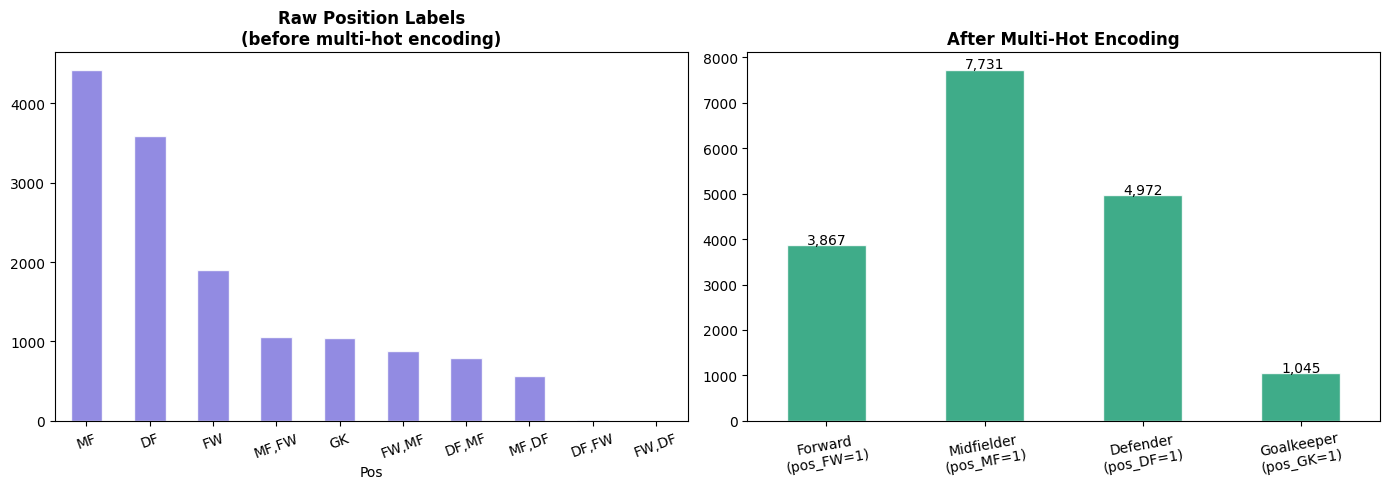

💾 Saved → reports/04_position_encoding.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
std_df['Pos'].value_counts().plot.bar(ax=ax, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.set_title('Raw Position Labels\n(before multi-hot encoding)', fontweight='bold')
ax.tick_params(axis='x', rotation=20)

ax = axes[1]
pos_counts = pd.Series({
    'Forward\n(pos_FW=1)':    pos_encoded['pos_FW'].sum(),
    'Midfielder\n(pos_MF=1)': pos_encoded['pos_MF'].sum(),
    'Defender\n(pos_DF=1)':   pos_encoded['pos_DF'].sum(),
    'Goalkeeper\n(pos_GK=1)': pos_encoded['pos_GK'].sum(),
})
pos_counts.plot.bar(ax=ax, color=COLORS[1], alpha=0.85, edgecolor='white')
ax.set_title('After Multi-Hot Encoding', fontweight='bold')
ax.tick_params(axis='x', rotation=10)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            f'{int(bar.get_height()):,}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(REPORTS / '04_position_encoding.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/04_position_encoding.png')

## 🔄 4 — STEP 1: Pivot FBref Stats (Long → Wide)

In [8]:
player_stats = all_stats[all_stats['level'] == 'player'].copy()

STD_KEEP = [
    'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min',
    'Performance_Gls', 'Performance_Ast',
    'Performance_PK', 'Performance_CrdY', 'Performance_CrdR',
]

SHOOT_KEEP = [
    'Standard_Sh', 'Standard_SoT%', 'Standard_G/Sh', 'Standard_G/SoT',
]

DEF_KEEP = ['Tackles_TklW', 'Int']

# ── Standard rows ─────────────────────────────────────────────────────
std_p = to_num_safe(player_stats[player_stats['stat_type'] == 'standard'].copy())
pos_enc = encode_positions(std_p['Pos'])

available_std = [c for c in STD_KEEP if c in std_p.columns]
fbref_wide = pd.concat([
    std_p[KEYS + ['Nation', 'Age'] + available_std].copy(),
    pos_enc
], axis=1)
fbref_wide = fbref_wide.drop_duplicates(subset=KEYS, keep='first')
print(f'Base (standard):  {len(fbref_wide):,} rows')

# ── Shooting rows ──────────────────────────────────────────────────────
shoot_p    = to_num_safe(player_stats[player_stats['stat_type'] == 'shooting'].copy())
avail_shoot = [c for c in SHOOT_KEEP
               if c in shoot_p.columns and get_col(shoot_p, c).notna().sum() > 100]
if avail_shoot:
    shoot_merge = shoot_p[KEYS + avail_shoot].drop_duplicates(subset=KEYS, keep='first')
    fbref_wide  = fbref_wide.merge(shoot_merge, on=KEYS, how='left')
    print(f'+ shooting:       {len(avail_shoot)} cols → {fbref_wide.shape}')

# ── Defense rows ───────────────────────────────────────────────────────
def_p    = to_num_safe(player_stats[player_stats['stat_type'] == 'defense'].copy())
avail_def = [c for c in DEF_KEEP
             if c in def_p.columns and get_col(def_p, c).notna().sum() > 100]
if avail_def:
    def_merge  = def_p[KEYS + avail_def].drop_duplicates(subset=KEYS, keep='first')
    fbref_wide = fbref_wide.merge(def_merge, on=KEYS, how='left')
    print(f'+ defense:        {len(avail_def)} cols → {fbref_wide.shape}')

# ── Other stat types (misc, possession, gca) ──────────────────────────
for stype in ['misc', 'possession', 'gca']:
    sub = to_num_safe(player_stats[player_stats['stat_type'] == stype].copy())
    if sub.empty:
        continue
    skip = set(KEYS + ['Pos', 'Nation', 'Age', 'Born', 'Matches', 'level', 'stat_type', '90s', 'Rk'])
    filled = [
        c for c in sub.columns
        if c not in skip
        and get_col(sub, c).notna().sum() > 200
    ]
    if filled:
        sub_m = sub[KEYS + filled].drop_duplicates(subset=KEYS, keep='first')
        # Avoid re-introducing duplicate column names on merge
        new_filled = [c for c in filled if c not in fbref_wide.columns]
        if new_filled:
            fbref_wide = fbref_wide.merge(sub_m[KEYS + new_filled], on=KEYS, how='left')
            print(f'+ {stype:<12}: {len(new_filled)} extra cols merged')

fbref_wide['name_norm'] = fbref_wide['Player'].apply(norm)

print(f'\n✅ FBref wide: {fbref_wide.shape[0]:,} rows × {fbref_wide.shape[1]} cols')
print(f'   Unique Player+Season: {fbref_wide.groupby(["Player", "season"]).ngroups:,}')

Base (standard):  14,292 rows
+ shooting:       4 cols → (14292, 24)
+ defense:        2 cols → (14292, 26)
+ misc        : 10 extra cols merged

✅ FBref wide: 14,292 rows × 37 cols
   Unique Player+Season: 13,517


## 💶 5 — STEP 2: Wages (parse + GBP→EUR + tier)

In [9]:
def parse_wage(v):
    if pd.isna(v): return np.nan
    cleaned = re.sub(r'[^\d.]', '', str(v))
    try: return float(cleaned)
    except: return np.nan

if all_wages.empty:
    print('⚠️  No wages data — wages will be NaN throughout')
    wages_clean = pd.DataFrame(columns=['name_norm', 'Squad', 'league', 'season',
                                         'weekly_eur', 'annual_eur', 'wage_tier'])
else:
    pw = all_wages[
        (all_wages['type'] == 'player') &
        all_wages['Player'].notna() &
        (~all_wages['Player'].astype(str).str.match(r'^\d|^Total|^Squad', na=False))
    ].copy()

    weekly_num_col = next((c for c in pw.columns if 'weekly' in c.lower() and 'num' in c.lower()), None)

    if weekly_num_col:
        pw['weekly_raw'] = pd.to_numeric(get_col(pw, weekly_num_col), errors='coerce')
        gbp_leagues = {'EPL', 'Bundesliga'}
        pw['weekly_eur'] = pw.apply(
            lambda r: r['weekly_raw'] * 1.17 if r.get('league') in gbp_leagues else r['weekly_raw'],
            axis=1
        ).round(0)
    elif 'Weekly Wages' in pw.columns:
        pw['weekly_eur'] = (get_col(pw, 'Weekly Wages').apply(parse_wage) * 1.17).round(0)
    else:
        print('⚠️  No wage column found — wages will be NaN')
        pw['weekly_eur'] = np.nan

    pw['annual_eur'] = (pw['weekly_eur'] * 52).round(0)

    q1, q2, q3 = pw['weekly_eur'].quantile([0.25, 0.50, 0.75])
    pw['wage_tier'] = pd.cut(
        pw['weekly_eur'],
        bins=[-np.inf, q1, q2, q3, np.inf],
        labels=['low', 'mid', 'high', 'elite']
    ).astype(str)

    pw['name_norm'] = pw['Player'].apply(norm)
    wages_clean = (
        pw[['name_norm', 'Squad', 'league', 'season', 'weekly_eur', 'annual_eur', 'wage_tier']]
        .drop_duplicates(['name_norm', 'season', 'league'], keep='first')
    )

    print(f'Wages clean: {len(wages_clean):,} rows')
    print(f'Weekly range: €{pw["weekly_eur"].min():,.0f} — €{pw["weekly_eur"].max():,.0f}')
    print(f'Tiers: {pw["wage_tier"].value_counts().to_dict()}')

Wages clean: 14,491 rows
Weekly range: €1 — €1,384,615
Tiers: {'high': 3711, 'low': 3668, 'mid': 3588, 'elite': 3539}


## 📈 6 — STEP 3: TM Market Value Features (latest + peak + trend)

In [10]:
val = valuations.copy()
val['date']                = pd.to_datetime(val['date'], errors='coerce')
val['market_value_in_eur'] = pd.to_numeric(val['market_value_in_eur'], errors='coerce')

latest = (
    val.sort_values('date').groupby('player_id').last().reset_index()
    [['player_id', 'market_value_in_eur', 'date']]
    .rename(columns={'market_value_in_eur': 'latest_value_eur', 'date': 'val_date'})
)
peak = (
    val.groupby('player_id')['market_value_in_eur'].max().reset_index()
    .rename(columns={'market_value_in_eur': 'peak_value_eur'})
)
earliest = (
    val.sort_values('date').groupby('player_id').first().reset_index()
    [['player_id', 'market_value_in_eur']]
    .rename(columns={'market_value_in_eur': 'earliest_value_eur'})
)

val_features = latest.merge(peak, on='player_id').merge(earliest, on='player_id')

val_features['value_trend'] = (
    val_features['latest_value_eur'] /
    val_features['earliest_value_eur'].replace(0, np.nan)
).round(3)

val_features['pct_of_peak'] = (
    val_features['latest_value_eur'] /
    val_features['peak_value_eur'].replace(0, np.nan)
).round(3)

print(f'Value features: {len(val_features):,} players')
print(f'Rising (trend>1):  {(val_features["value_trend"] > 1).sum():,}')
print(f'Declining (<1):    {(val_features["value_trend"] < 1).sum():,}')
print(f'At peak (>0.9):    {(val_features["pct_of_peak"] > 0.9).sum():,}')

Value features: 39,361 players
Rising (trend>1):  27,399
Declining (<1):    7,025
At peak (>0.9):    12,350


## 🏃 7 — STEP 4: Career & Form Stats from Appearances

In [11]:
apps = appearances.copy()
apps['date'] = pd.to_datetime(apps['date'], errors='coerce')

career = apps.groupby('player_id').agg(
    career_games   = ('appearance_id', 'count'),
    career_goals   = ('goals',          'sum'),
    career_assists = ('assists',         'sum'),
    career_minutes = ('minutes_played',  'sum'),
    career_yellows = ('yellow_cards',    'sum'),
    career_reds    = ('red_cards',       'sum'),
).reset_index()

career_p90 = career['career_minutes'].replace(0, np.nan) / 90
career['career_goals_p90']   = (career['career_goals']   / career_p90).round(3)
career['career_assists_p90'] = (career['career_assists']  / career_p90).round(3)
career['career_g_a_p90']     = ((career['career_goals'] + career['career_assists']) / career_p90).round(3)

cutoff = apps['date'].max() - pd.DateOffset(months=12)
recent = apps[apps['date'] >= cutoff].groupby('player_id').agg(
    form_games   = ('appearance_id', 'count'),
    form_goals   = ('goals',          'sum'),
    form_assists = ('assists',         'sum'),
    form_minutes = ('minutes_played',  'sum'),
).reset_index()
form_p90 = recent['form_minutes'].replace(0, np.nan) / 90
recent['form_goals_p90']   = (recent['form_goals']   / form_p90).round(3)
recent['form_assists_p90'] = (recent['form_assists']  / form_p90).round(3)

tr_stats = transfers.groupby('player_id').agg(
    total_transfers = ('transfer_fee', 'count'),
    max_fee_eur     = ('transfer_fee', 'max'),
).reset_index()

print(f'Career stats:   {len(career):,} players')
print(f'Recent form:    {len(recent):,} players')
print(f'Transfer stats: {len(tr_stats):,} players')

Career stats:   28,665 players
Recent form:    8,930 players
Transfer stats: 20,855 players


## 🏥 8 — STEP 5: Injury Features from TM_INJURIES

In [12]:
if tm_injuries.empty:
    print('⚠️  TM_INJURIES not loaded — injury features will be null')
    injury_features = pd.DataFrame(columns=['name_norm',
        'total_injuries', 'total_days_out', 'total_games_missed',
        'avg_days_per_inj', 'max_single_injury', 'most_common_injury',
        'injury_risk_score', 'injury_risk_label'])
else:
    inj = tm_injuries.copy()
    # TM stores durations as text ('6 days'), so extract the number before converting
    inj['days_out']     = pd.to_numeric(inj['days_out'].astype(str).str.extract(r'(\d+)')[0], errors='coerce').fillna(0)
    inj['games_missed'] = pd.to_numeric(inj['games_missed'], errors='coerce').fillna(0)
    inj['from_date']    = pd.to_datetime(inj['from_date'],   errors='coerce')

    # ── Determine the name column to group on ─────────────────────────
    # TM_INJURIES may have 'player_name' or 'tm_player_id' depending on scraper version.
    # Priority: join via tm_player_id → TM_PLAYER_VALUES bridge (most reliable)
    # Fallback: group directly on player_name (name-based, less reliable)

    if 'tm_player_id' in inj.columns and not tm_values.empty and 'tm_player_id' in tm_values.columns:
        # Bridge: tm_player_id → canonical player name
        bridge = (
            tm_values[['tm_player_id', 'player_name']]
            .drop_duplicates('tm_player_id')
        )
        inj = inj.merge(bridge, on='tm_player_id', how='left', suffixes=('_inj', '_bridge'))
        name_col = 'player_name_bridge' if 'player_name_bridge' in inj.columns else 'player_name'
    else:
        name_col = 'player_name'

    inj['_group_name'] = inj[name_col].fillna('').apply(norm)

    agg = inj.groupby('_group_name').agg(
        total_injuries     = ('days_out',     'count'),
        total_days_out     = ('days_out',     'sum'),
        total_games_missed = ('games_missed', 'sum'),
        avg_days_per_inj   = ('days_out',     'mean'),
        max_single_injury  = ('days_out',     'max'),
        last_injury_date   = ('from_date',    'max'),
    ).reset_index().rename(columns={'_group_name': 'name_norm'})

    common = (
        inj.groupby('_group_name')['injury_type']
        .agg(lambda x: x.value_counts().index[0] if len(x) > 0 else 'none')
        .reset_index().rename(columns={'_group_name': 'name_norm', 'injury_type': 'most_common_injury'})
    )
    agg = agg.merge(common, on='name_norm', how='left')

    p95 = agg['total_days_out'].quantile(0.95)
    agg['injury_risk_score'] = (agg['total_days_out'] / p95 * 100).clip(0, 100).round(1)
    agg['injury_risk_label'] = pd.cut(
        agg['injury_risk_score'],
        bins=[-1, 10, 30, 60, 100],
        labels=['minimal', 'low_risk', 'medium_risk', 'high_risk']
    ).astype(str)

    injury_features = agg
    print(f'Injury features: {len(injury_features):,} players')
    print(f'Risk breakdown:  {agg["injury_risk_label"].value_counts().to_dict()}')

Injury features: 266 players
Risk breakdown:  {}


## 🧩 9 — STEP 6: Build TM Master (profile + all features)

In [13]:
tm = players.copy()
tm['date_of_birth'] = pd.to_datetime(tm['date_of_birth'], errors='coerce')
tm['age']           = ((pd.Timestamp.now() - tm['date_of_birth']).dt.days / 365.25).round(1)
tm['foot']          = tm['foot'].fillna('unknown')

# Fill height with sub_position median
tm['height_in_cm'] = tm['height_in_cm'].fillna(
    tm.groupby('sub_position')['height_in_cm'].transform('median')
).fillna(tm['height_in_cm'].median())

tm['name_norm'] = tm['name'].apply(norm)

# Fill market value nulls from TM scraped values
if not tm_values.empty and 'tm_player_id' in tm_values.columns:
    def _parse_mv(v):
        if pd.isna(v) or isinstance(v, float): return v
        v = str(v).replace('€', '').replace(',', '.').strip().lower()
        try:
            if 'm' in v: return float(v.replace('m', '')) * 1e6
            if 'k' in v: return float(v.replace('k', '')) * 1e3
            return float(v)
        except: return np.nan

    tm_vals_latest = (
        tm_values.sort_values('season_id', ascending=False)
        .drop_duplicates('tm_player_id', keep='first')
        [['tm_player_id', 'market_value_eur']]
    )
    tm_vals_latest['mv_scraped'] = tm_vals_latest['market_value_eur'].apply(_parse_mv)
    tm_vals_latest['tm_player_id'] = tm_vals_latest['tm_player_id'].astype(str)
    tm['player_id_str'] = tm['player_id'].astype(str)
    tm = tm.merge(tm_vals_latest[['tm_player_id', 'mv_scraped']],
                  left_on='player_id_str', right_on='tm_player_id', how='left')
    n_filled = tm['market_value_in_eur'].isna().sum()
    tm['market_value_in_eur'] = tm['market_value_in_eur'].fillna(tm['mv_scraped'])
    print(f'Filled {n_filled - tm["market_value_in_eur"].isna().sum():,} null market values from TM scraped')

tm.drop(columns=[c for c in ['image_url', 'url', 'player_code', 'city_of_birth',
                               'first_name', 'last_name', 'current_national_team_id',
                               'player_id_str', 'tm_player_id', 'mv_scraped']
                 if c in tm.columns], inplace=True)

tm_master = (
    tm
    .merge(val_features, on='player_id', how='left')
    .merge(career,       on='player_id', how='left')
    .merge(recent,       on='player_id', how='left')
    .merge(tr_stats,     on='player_id', how='left')
)

tm_master['market_value_eur'] = (
    tm_master['latest_value_eur'].fillna(tm_master['market_value_in_eur'])
)

print(f'TM master: {len(tm_master):,} players × {len(tm_master.columns)} cols')

Filled 128 null market values from TM scraped
TM master: 47,702 players × 45 cols


## 🔗 10 — STEP 7: Join FBref + TM (exact + fuzzy)

In [14]:
tm_master['name_norm'] = tm_master['name'].apply(norm)

# Exact join
master = fbref_wide.merge(
    tm_master.drop(columns=['name'], errors='ignore'),
    on='name_norm', how='left', suffixes=('', '_tm')
)

matched = master['player_id'].notna().sum()
total   = len(master)
print(f'Exact join: {matched:,}/{total:,} matched ({matched/total*100:.1f}%)')

# Fuzzy matching for remaining unmatched players
unmatched_names = master[master['player_id'].isna()]['name_norm'].unique()
tm_name_list    = tm_master['name_norm'].dropna().unique().tolist()

print(f'Fuzzy matching {len(unmatched_names):,} unmatched players...')

fuzzy_map = {}
try:
    from rapidfuzz import process, fuzz
    for name in unmatched_names:
        if not name: continue
        res = process.extractOne(name, tm_name_list, scorer=fuzz.token_sort_ratio)
        if res and res[1] >= 85:
            fuzzy_map[name] = res[0]
    print(f'  (using rapidfuzz)')
except ImportError:
    from difflib import get_close_matches
    for name in unmatched_names:
        if not name: continue
        m = get_close_matches(name, tm_name_list, n=1, cutoff=0.85)
        if m: fuzzy_map[name] = m[0]
    print(f'  (using difflib — install rapidfuzz for better results)')

print(f'Fuzzy matched: {len(fuzzy_map):,} additional players')

# Apply fuzzy matches
if fuzzy_map:
    tm_idx  = tm_master.set_index('name_norm')
    tm_cols = [c for c in tm_master.columns if c != 'name_norm']
    for fb_name, tm_name in fuzzy_map.items():
        if tm_name not in tm_idx.index: continue
        row = tm_idx.loc[tm_name]
        # .loc[tm_name] can return a DataFrame if name is duplicated in TM index
        if isinstance(row, pd.DataFrame):
            row = row.iloc[0]
        idx = master[master['name_norm'] == fb_name].index
        for col in tm_cols:
            mc = col if col in master.columns else col + '_tm'
            if mc in master.columns and col in row.index:
                master.loc[idx, mc] = row[col]

final_matched = master['player_id'].notna().sum()
print(f'After fuzzy:   {final_matched:,}/{total:,} ({final_matched/total*100:.1f}%)')

# Merge wages
master = master.merge(
    wages_clean, on=['name_norm', 'league', 'season'], how='left', suffixes=('', '_w')
)

# Merge injury features (name-based join on normalized name)
master = master.merge(
    injury_features, on='name_norm', how='left', suffixes=('', '_inj')
)

print(f'\n✅ Master: {master.shape[0]:,} rows × {master.shape[1]} cols')

Exact join: 14,302/15,304 matched (93.5%)
Fuzzy matching 487 unmatched players...
  (using difflib — install rapidfuzz for better results)
Fuzzy matched: 193 additional players
After fuzzy:   14,706/15,304 (96.1%)

✅ Master: 15,304 rows × 93 cols


## ⚙️ 11 — STEP 8: Compute All Per-90 KPIs

In [20]:
df = master.copy()

# Base playing time
df['minutes_played'] = pd.to_numeric(get_col(df, 'Playing Time_Min'),    errors='coerce').fillna(0)
df['games_played']   = pd.to_numeric(get_col(df, 'Playing Time_MP'),     errors='coerce').fillna(0)
df['starts']         = pd.to_numeric(get_col(df, 'Playing Time_Starts'), errors='coerce').fillna(0)
df['p90']            = (df['minutes_played'] / 90).replace(0, np.nan)

# Availability % this season
season_games = df['league'].map({
    'EPL': 38, 'LaLiga': 38, 'SerieA': 38, 'Bundesliga': 34, 'Ligue1': 38
}).fillna(38)
df['availability_pct'] = (df['games_played'] / season_games * 100).clip(0, 100).round(1)

# Raw stats (using get_col to guard against duplicate columns)
gls  = pd.to_numeric(get_col(df, 'Performance_Gls'), errors='coerce')
ast  = pd.to_numeric(get_col(df, 'Performance_Ast'), errors='coerce')
sh   = pd.to_numeric(get_col(df, 'Standard_Sh'),     errors='coerce')
pk   = pd.to_numeric(get_col(df, 'Performance_PK'),  errors='coerce')
cdy  = pd.to_numeric(get_col(df, 'Performance_CrdY'), errors='coerce')
cdr  = pd.to_numeric(get_col(df, 'Performance_CrdR'), errors='coerce')
tkl  = pd.to_numeric(get_col(df, 'Tackles_TklW'),    errors='coerce')
int_ = pd.to_numeric(get_col(df, 'Int'),             errors='coerce')

df['goals']             = gls.fillna(0)
df['assists']           = ast.fillna(0)
df['penalties_scored']  = pk.fillna(0)
df['yellow_cards']      = cdy.fillna(0)
df['red_cards']         = cdr.fillna(0)
df['tackles_won']       = tkl.fillna(0)
df['interceptions']     = int_.fillna(0)

# Per-90
df['goals_p90']         = (gls  / df['p90']).round(3)
df['assists_p90']       = (ast  / df['p90']).round(3)
df['g_a_p90']           = ((gls + ast) / df['p90']).round(3)
df['shots_p90']         = (sh   / df['p90']).round(3)
df['tackles_won_p90']   = (tkl  / df['p90']).round(3)
df['interceptions_p90'] = (int_ / df['p90']).round(3)
df['def_actions_p90']   = ((tkl + int_) / df['p90']).round(3)
df['yellow_p90']        = (cdy  / df['p90']).round(3)
df['red_p90']           = (cdr  / df['p90']).round(3)

# Shooting quality (already rate-based)
df['shot_accuracy_pct'] = pd.to_numeric(get_col(df, 'Standard_SoT%'),  errors='coerce')
df['conversion_rate']   = pd.to_numeric(get_col(df, 'Standard_G/Sh'),  errors='coerce')
df['finishing_quality'] = pd.to_numeric(get_col(df, 'Standard_G/SoT'), errors='coerce')

computed_kpis = [
    'goals_p90', 'assists_p90', 'g_a_p90', 'shots_p90',
    'tackles_won_p90', 'interceptions_p90', 'def_actions_p90',
    'yellow_p90', 'shot_accuracy_pct', 'conversion_rate', 'finishing_quality',
    'availability_pct'
]

print('Per-90 KPIs computed:')
for c in computed_kpis:
    nn  = df[c].notna().sum()
    med = df[c].median()
    print(f'  {c:<30} {nn:,} non-null  median: {med:.3f}')

Per-90 KPIs computed:
  goals_p90                      15,304 non-null  median: 0.000
  assists_p90                    15,304 non-null  median: 0.000
  g_a_p90                        15,304 non-null  median: 0.087
  shots_p90                      14,765 non-null  median: 0.826
  tackles_won_p90                14,357 non-null  median: 0.828
  interceptions_p90              14,357 non-null  median: 0.698
  def_actions_p90                14,357 non-null  median: 1.682
  yellow_p90                     15,304 non-null  median: 0.149
  shot_accuracy_pct              12,063 non-null  median: 32.500
  conversion_rate                12,063 non-null  median: 0.060
  finishing_quality              10,305 non-null  median: 0.250
  availability_pct               15,304 non-null  median: 55.300


## 📊 12 — STEP 9: Composite Scores (0–10 scale)

In [21]:
def minmax10(s, clip_q=0.99):
    """Normalize series to 0–10, clipping outliers at given quantile."""
    s = s.copy().fillna(0)
    s = s.clip(upper=s.quantile(clip_q))
    mn, mx = s.min(), s.max()
    if mx == mn:
        return pd.Series(5.0, index=s.index)
    return ((s - mn) / (mx - mn) * 10).round(2)

# Attack score
df['attack_score'] = sum(minmax10(s) * w for s, w in [
    (df['goals_p90'].fillna(0),       0.35),
    (df['assists_p90'].fillna(0),     0.25),
    (df['shots_p90'].fillna(0),       0.20),
    (df['conversion_rate'].fillna(0), 0.20),
]).round(2)

# Defense score
df['defense_score'] = sum(minmax10(s) * w for s, w in [
    (df['tackles_won_p90'].fillna(0),   0.40),
    (df['interceptions_p90'].fillna(0), 0.40),
    (df['def_actions_p90'].fillna(0),   0.20),
]).round(2)

# Discipline score (inverted)
df['discipline_score'] = (10 - minmax10(df['yellow_p90'].fillna(0))).round(2)

# Shooting quality score
if df['shot_accuracy_pct'].notna().sum() > 100:
    df['shooting_quality_score'] = sum(minmax10(s) * w for s, w in [
        (df['shot_accuracy_pct'].fillna(0), 0.50),
        (df['conversion_rate'].fillna(0),   0.30),
        (df['finishing_quality'].fillna(0), 0.20),
    ]).round(2)

# Overall scouting score
df['overall_score'] = (
    df['attack_score']     * 0.40 +
    df['defense_score']    * 0.35 +
    df['discipline_score'] * 0.25
).round(2)

for score in ['attack_score', 'defense_score', 'discipline_score', 'overall_score']:
    print(f'{score:<25} mean={df[score].mean():.2f}  std={df[score].std():.2f}  '
          f'min={df[score].min():.2f}  max={df[score].max():.2f}')

attack_score              mean=1.38  std=1.45  min=0.00  max=9.63
defense_score             mean=1.86  std=1.53  min=0.00  max=10.00
discipline_score          mean=8.79  std=1.54  min=0.00  max=10.00
overall_score             mean=3.40  std=0.79  min=0.00  max=8.00


## 💎 13 — STEP 10: Value Efficiency

In [22]:
mv = pd.to_numeric(
    get_col(df, 'market_value_eur') if 'market_value_eur' in df.columns
    else get_col(df, 'market_value_in_eur'),
    errors='coerce'
)

df['value_efficiency'] = (
    (df['goals'] + df['assists']) / (mv / 1_000_000).replace(0, np.nan)
).round(3)

df['value_efficiency_p90'] = (
    df['g_a_p90'] / (mv / 1_000_000).replace(0, np.nan)
).round(4)

age_col = 'Age' if 'Age' in df.columns else 'age'
age = pd.to_numeric(get_col(df, age_col), errors='coerce').fillna(25)
df['youth_value_score'] = (
    df['value_efficiency'] * (1 + (25 - age.clip(15, 35)) / 25)
).round(3)

print(f'value_efficiency non-null: {df["value_efficiency"].notna().sum():,}\n')

print('Top 10 value-efficient players (min 5 G+A, any season):')
top = (
    df[(df['goals'] + df['assists']) >= 5]
    .nlargest(10, 'value_efficiency')
    [['Player', 'Squad', 'league', 'season', 'goals', 'assists', 'market_value_eur', 'value_efficiency']]
).copy()
if 'market_value_eur' in top.columns:
    top['value_M€'] = (pd.to_numeric(top['market_value_eur'], errors='coerce') / 1e6).round(1)
    top.drop(columns=['market_value_eur'], inplace=True)
print(top.to_string(index=False))

value_efficiency non-null: 14,500

Top 10 value-efficient players (min 5 G+A, any season):
         Player            Squad league    season  goals  assists  value_efficiency  value_M€
  Callum Wilson Newcastle United    EPL 2022-2023 18.000    5.000           920.000     0.000
  Callum Wilson Newcastle United    EPL 2020-2021 12.000    5.000           680.000     0.000
Álvaro González        Marseille Ligue1 2020-2021  2.000    3.000           500.000     0.000
  Callum Wilson Newcastle United    EPL 2023-2024  9.000    1.000           400.000     0.000
     João Pedro         Cagliari SerieA 2020-2021 16.000    3.000           380.000     0.000
  Malick Fofana             Lyon Ligue1 2024-2025  5.000    4.000           360.000     0.000
     João Pedro         Cagliari SerieA 2021-2022 13.000    4.000           340.000     0.000
  Callum Wilson Newcastle United    EPL 2021-2022  8.000    0.000           320.000     0.000
     João Pedro         Brighton    EPL 2024-2025 10.000    6.0

## 🧹 14 — Final Clean, Select Features & Save

In [23]:
# Minimum 90 minutes played
df_final = df[df['minutes_played'] >= 90].copy()
print(f'After 90-min filter: {len(df_final):,} (removed {len(df) - len(df_final):,})')

FINAL_FEATURES = {
    'IDENTITY':     ['Player', 'name_norm', 'Nation', 'Age', 'primary_pos',
                     'pos_FW', 'pos_MF', 'pos_DF', 'pos_GK', 'is_versatile',
                     'Squad', 'league', 'season',
                     'country_of_citizenship', 'sub_position', 'foot', 'height_in_cm'],
    'PLAYING_TIME': ['games_played', 'starts', 'minutes_played', 'availability_pct'],
    'ATT_RAW':      ['goals', 'assists', 'penalties_scored'],
    'ATT_P90':      ['goals_p90', 'assists_p90', 'g_a_p90', 'shots_p90'],
    'SHOOTING':     ['shot_accuracy_pct', 'conversion_rate', 'finishing_quality'],
    'DEF_RAW':      ['tackles_won', 'interceptions'],
    'DEF_P90':      ['tackles_won_p90', 'interceptions_p90', 'def_actions_p90'],
    'DISCIPLINE':   ['yellow_cards', 'red_cards', 'yellow_p90', 'red_p90'],
    'MARKET':       ['market_value_eur', 'peak_value_eur', 'value_trend', 'pct_of_peak',
                     'highest_market_value_in_eur'],
    'WAGES':        ['weekly_eur', 'annual_eur', 'wage_tier'],
    'CAREER':       ['career_games', 'career_goals', 'career_assists',
                     'career_goals_p90', 'career_g_a_p90'],
    'FORM':         ['form_games', 'form_goals', 'form_assists', 'form_goals_p90'],
    'INJURY':       ['total_injuries', 'total_days_out', 'avg_days_per_inj',
                     'injury_risk_score', 'injury_risk_label'],
    'TRANSFERS':    ['total_transfers', 'max_fee_eur'],
    'SCORES':       ['attack_score', 'defense_score', 'discipline_score',
                     'overall_score', 'value_efficiency'],
}

all_wanted  = [c for cols in FINAL_FEATURES.values() for c in cols]
final_cols  = [c for c in all_wanted if c in df_final.columns]
missing     = [c for c in all_wanted if c not in df_final.columns]

print(f'Features selected: {len(final_cols)}')
if missing:
    print(f'Features missing:  {missing}')

df_out = df_final[final_cols].copy()
df_out.drop_duplicates(subset=['Player', 'season'], keep='first', inplace=True)

mv_col = 'market_value_eur' if 'market_value_eur' in df_out.columns else 'market_value_in_eur'
if mv_col in df_out.columns:
    df_out.sort_values(mv_col, ascending=False, na_position='last', inplace=True)

df_out.to_csv(PROCESSED / 'master_scouting_dataset.csv', index=False)

print(f'\n{"="*60}')
print(f'  ✅ SAVED: master_scouting_dataset.csv')
print(f'  Rows:    {len(df_out):,}')
print(f'  Columns: {len(df_out.columns)}')
print(f'{"="*60}')
print(df_out[['Player', 'Age', 'primary_pos', 'pos_FW', 'pos_MF', 'pos_DF',
              'Squad', 'league', 'season', 'goals_p90', 'attack_score',
              'value_efficiency']].head(8).to_string(index=False))

After 90-min filter: 13,350 (removed 1,954)
Features selected: 69

  ✅ SAVED: master_scouting_dataset.csv
  Rows:    11,888
  Columns: 69
        Player    Age primary_pos  pos_FW  pos_MF  pos_DF               Squad     league    season  goals_p90  attack_score  value_efficiency
 Kylian Mbappé 23.000     Forward       1       0       0 Paris Saint-Germain     Ligue1 2022-2023      0.926         6.530             0.170
Erling Haaland 24.000     Forward       1       0       0     Manchester City        EPL 2024-2025      0.724         5.190             0.125
Erling Haaland 20.000     Forward       1       0       0            Dortmund Bundesliga 2020-2021      1.010         6.720             0.165
Erling Haaland 23.000     Forward       1       1       0     Manchester City        EPL 2023-2024      0.952         6.410             0.160
 Kylian Mbappé 21.000     Forward       1       1       0 Paris Saint-Germain     Ligue1 2020-2021      1.021         6.770             0.170
Erling Haa

## 📊 15 — Validation Charts

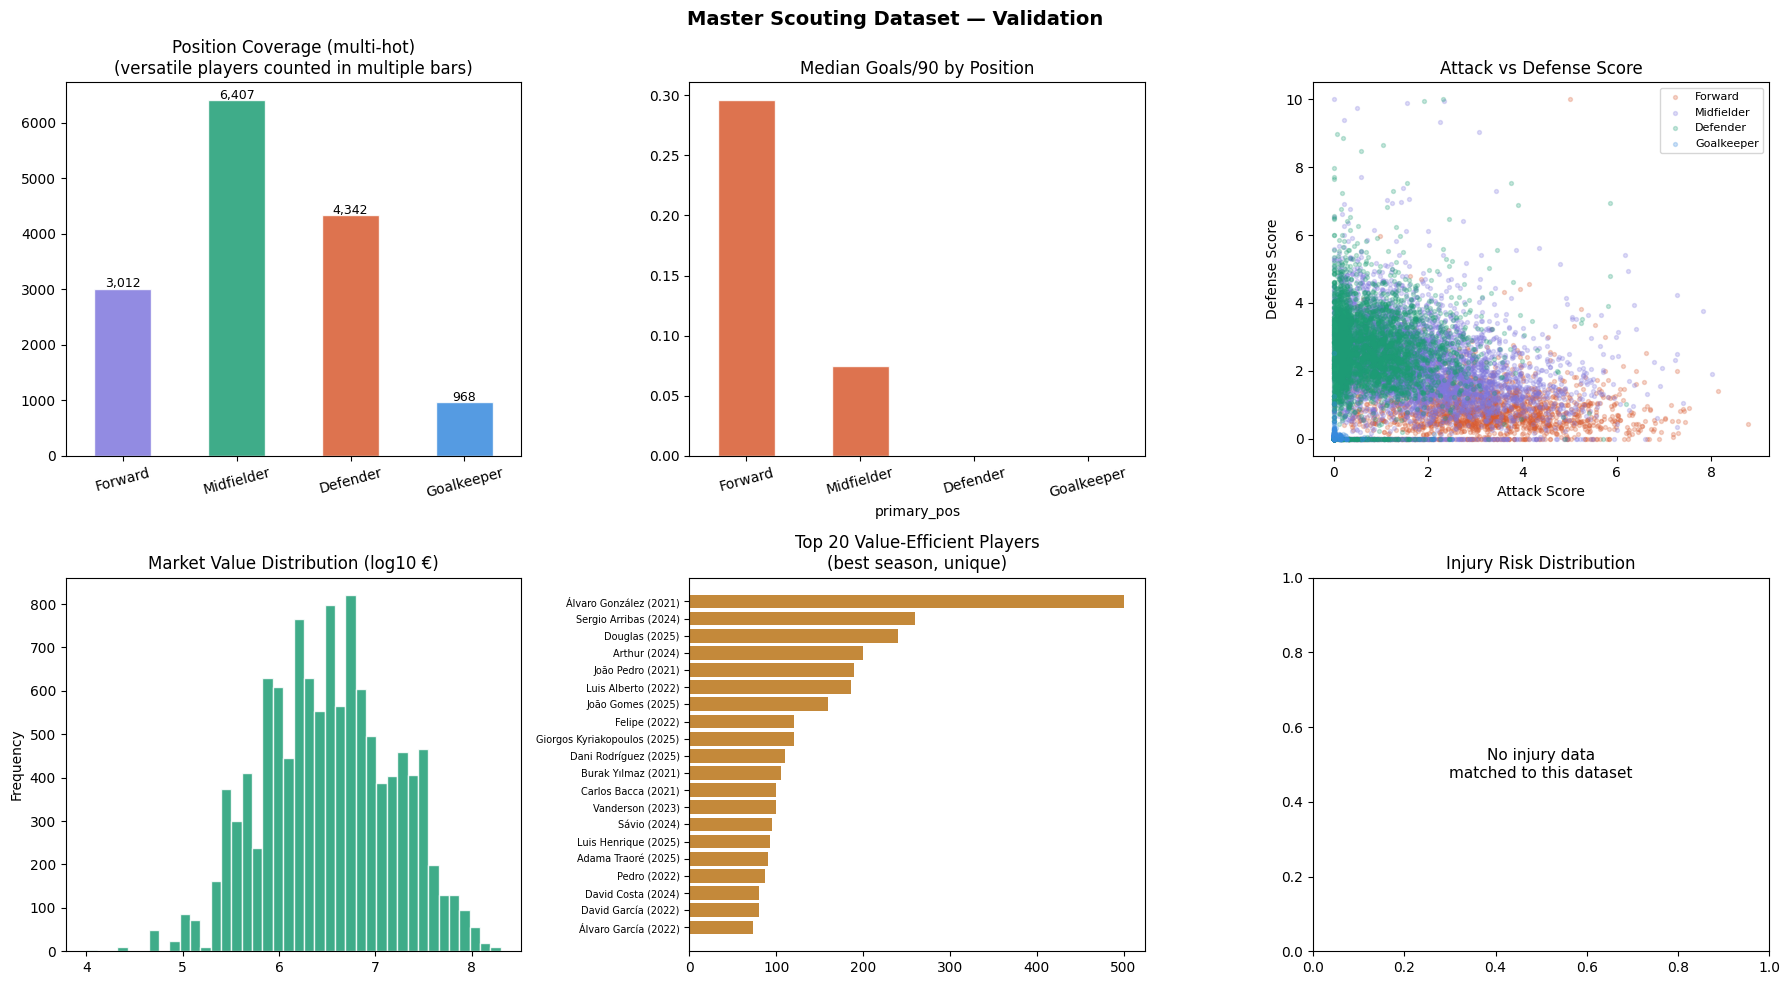

💾 Saved → reports/05_master_validation.png


In [24]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Master Scouting Dataset — Validation', fontsize=14, fontweight='bold')

# Position distribution
ax = axes[0, 0]
pos_dist = pd.Series({
    'Forward':    df_out['pos_FW'].sum(),
    'Midfielder': df_out['pos_MF'].sum(),
    'Defender':   df_out['pos_DF'].sum(),
    'Goalkeeper': df_out['pos_GK'].sum()
})
pos_dist.plot.bar(ax=ax, color=COLORS, alpha=0.85, edgecolor='white')
ax.set_title('Position Coverage (multi-hot)\n(versatile players counted in multiple bars)')
ax.tick_params(axis='x', rotation=15)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f'{int(bar.get_height()):,}', ha='center', fontsize=9)

# Goals p90 by position
ax = axes[0, 1]
if 'goals_p90' in df_out.columns and 'primary_pos' in df_out.columns:
    df_out.groupby('primary_pos')['goals_p90'].median().sort_values(ascending=False).plot.bar(
        ax=ax, color=COLORS[2], alpha=0.85, edgecolor='white')
    ax.set_title('Median Goals/90 by Position')
    ax.tick_params(axis='x', rotation=15)

# Attack vs Defense scatter
ax = axes[0, 2]
if 'attack_score' in df_out.columns and 'defense_score' in df_out.columns:
    for pos, color in [('Forward', COLORS[2]), ('Midfielder', COLORS[0]),
                        ('Defender', COLORS[1]), ('Goalkeeper', COLORS[3])]:
        mask = df_out['primary_pos'] == pos
        ax.scatter(df_out[mask]['attack_score'], df_out[mask]['defense_score'],
                   alpha=0.25, s=8, color=color, label=pos)
    ax.set_title('Attack vs Defense Score')
    ax.legend(fontsize=8)
    ax.set_xlabel('Attack Score')
    ax.set_ylabel('Defense Score')

# Market value distribution
ax = axes[1, 0]
if 'market_value_eur' in df_out.columns:
    vals = pd.to_numeric(df_out['market_value_eur'], errors='coerce').dropna()
    vals = vals[vals > 0]
    np.log10(vals).plot.hist(bins=40, ax=ax, color=COLORS[1], alpha=0.85, edgecolor='white')
    ax.set_title('Market Value Distribution (log10 €)')

# Top value-efficient players
ax = axes[1, 1]
if 'value_efficiency' in df_out.columns:
    best = (
        df_out[df_out['value_efficiency'].notna()]
        .sort_values('value_efficiency', ascending=False)
        .drop_duplicates('Player', keep='first')
        .head(20)
    )
    ax.barh(range(len(best)), best['value_efficiency'].values, color=COLORS[4], alpha=0.85)
    ax.set_yticks(range(len(best)))
    ax.set_yticklabels(
        [f"{row['Player']} ({row['season'][-4:]})" for _, row in best.iterrows()],
        fontsize=7
    )
    ax.set_title('Top 20 Value-Efficient Players\n(best season, unique)')
    ax.invert_yaxis()

# Injury risk
ax = axes[1, 2]
if 'injury_risk_label' in df_out.columns:
    # Filter out NaN and the string 'nan' that pd.cut produces after .astype(str)
    risk_counts = (
        df_out['injury_risk_label']
        .loc[~df_out['injury_risk_label'].isin([np.nan, 'nan', 'None', ''])]
        .value_counts()
    )
    if not risk_counts.empty:
        risk_counts.plot.bar(ax=ax, color=COLORS[5], alpha=0.85, edgecolor='white')
        ax.set_title('Injury Risk Distribution')
        ax.tick_params(axis='x', rotation=15)
    else:
        ax.text(0.5, 0.5, 'No injury data\nmatched to this dataset',
                ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.set_title('Injury Risk Distribution')

plt.tight_layout()
plt.savefig(REPORTS / '05_master_validation.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/05_master_validation.png')

## 🖨️ 16 — Summary Print for Claude

In [25]:
num_features = df_out.select_dtypes(include=np.number).columns.tolist()

summary = {
    'master_dataset': {
        'rows':             len(df_out),
        'total_columns':    len(df_out.columns),
        'numeric_features': len(num_features),
        'all_columns':      list(df_out.columns),
        'numeric_columns':  num_features,
    },
    'coverage': {
        'unique_players': int(df_out['Player'].nunique()),
        'seasons':        sorted(df_out['season'].unique().tolist()),
        'leagues':        sorted(df_out['league'].unique().tolist()),
        'positions_multi': {
            'pos_FW':            int(df_out['pos_FW'].sum()),
            'pos_MF':            int(df_out['pos_MF'].sum()),
            'pos_DF':            int(df_out['pos_DF'].sum()),
            'pos_GK':            int(df_out['pos_GK'].sum()),
            'versatile_players': int(df_out['is_versatile'].sum()),
        },
    },
    'data_quality': {
        c: f"{df_out[c].isna().mean()*100:.1f}%"
        for c in ['goals_p90', 'assists_p90', 'attack_score', 'defense_score',
                  'market_value_eur', 'weekly_eur', 'injury_risk_score',
                  'value_efficiency', 'tackles_won_p90']
        if c in df_out.columns
    },
    'feature_groups': {
        k: [c for c in v if c in df_out.columns]
        for k, v in FINAL_FEATURES.items()
    },
    'correlation_analysis': {
        'dropped_redundant': list(REDUNDANT_COLS.keys()),
        'reason_summary': 'Dropped 15 columns: 6 perfectly derived (r=1.0), 5 FBref pre-computed per-90, 4 high-correlation duplicates',
    },
    'position_encoding': {
        'method':        'multi-hot (not single label)',
        'columns':       ['pos_FW', 'pos_MF', 'pos_DF', 'pos_GK', 'primary_pos', 'is_versatile'],
        'versatile_pct': f"{df_out['is_versatile'].mean()*100:.1f}%",
        'why': 'Recommendation engine uses pos_MF=1 to find all midfielders including versatile MF,FW players',
    },
    'ml_ready': {
        'model_1_knn_similarity': f'READY — {len(num_features)} numeric features for cosine similarity',
        'model_2_xgboost':        'READY — all features + labels available',
        'model_3_kmeans':         'READY — subset by primary_pos, cluster on per-90 stats',
        'recommendation_engine':  'READY — filter by pos_FW/MF/DF/GK (multi-hot), rank by overall_score + value_efficiency',
    },
    'next_notebook': 'notebook 04 — Model 1: KNN Similarity Engine',
}

print('=' * 65)
print('  NB03 COMPLETE — SUMMARY FOR CLAUDE')
print('=' * 65)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED / 'nb03_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f"""
{'='*65}
  MASTER DATASET READY:
  Rows:              {summary['master_dataset']['rows']:,}
  Numeric features:  {summary['master_dataset']['numeric_features']}
  Unique players:    {summary['coverage']['unique_players']:,}
  Versatile players: {summary['coverage']['positions_multi']['versatile_players']:,}
  Dropped redundant: {len(summary['correlation_analysis']['dropped_redundant'])} columns
  → NEXT: notebook 04 — KNN Similarity Model
{'='*65}
""")

  NB03 COMPLETE — SUMMARY FOR CLAUDE
{
  "master_dataset": {
    "rows": 11888,
    "total_columns": 69,
    "numeric_features": 57,
    "all_columns": [
      "Player",
      "name_norm",
      "Nation",
      "Age",
      "primary_pos",
      "pos_FW",
      "pos_MF",
      "pos_DF",
      "pos_GK",
      "is_versatile",
      "Squad",
      "league",
      "season",
      "country_of_citizenship",
      "sub_position",
      "foot",
      "height_in_cm",
      "games_played",
      "starts",
      "minutes_played",
      "availability_pct",
      "goals",
      "assists",
      "penalties_scored",
      "goals_p90",
      "assists_p90",
      "g_a_p90",
      "shots_p90",
      "shot_accuracy_pct",
      "conversion_rate",
      "finishing_quality",
      "tackles_won",
      "interceptions",
      "tackles_won_p90",
      "interceptions_p90",
      "def_actions_p90",
      "yellow_cards",
      "red_cards",
      "yellow_p90",
      "red_p90",
      "market_value_eur",
      "peak_